In [1]:
from google.colab import files

uploaded = files.upload()

Saving web_traffic_analytics_v2 (2).csv to web_traffic_analytics_v2 (2).csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print("Uploaded files:", os.listdir())

Uploaded files: ['.config', 'web_traffic_analytics_v2 (2).csv', 'sample_data']


In [6]:
import os

print(os.listdir())

['.config', 'web_traffic_analytics_v2 (2).csv', 'sample_data']


In [8]:
import os

print("Current directory:", os.getcwd())
print("\nAvailable files:")

for file in os.listdir('/content'):
    print(file)

Current directory: /content

Available files:
.config
web_traffic_analytics_v2 (2).csv
sample_data


In [9]:
from google.colab import files

uploaded = files.upload()

Saving web_traffic_analytics_v2 (2).csv to web_traffic_analytics_v2 (2) (1).csv


In [10]:
import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (900, 12)


,SessionID,Date,LandingPage,Source,Campaign,DeviceCategory,Region,SessionDurationSec,PageViews,StartedRegistration,Registered,Bounced
0,SESS-500001,2026-02-15,/,Email,none,Mobile,Delhi,243,3,Yes,No,No
1,SESS-500002,2026-06-03,/,Direct,none,Mobile,Karnataka,268,4,No,No,No
2,SESS-500003,2026-04-14,/register,Google Organic,starter,Desktop,Telangana,360,3,Yes,Yes,No
3,SESS-500004,2026-03-31,/register,Email,campus,Desktop,Maharashtra,282,5,Yes,Yes,No
4,SESS-500005,2026-04-24,/programs,Direct,none,Mobile,Tamil Nadu,232,2,No,No,No


In [11]:
print("Dataset Shape:", df.shape)

Dataset Shape: (900, 12)


In [12]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['SessionID', 'Date', 'LandingPage', 'Source', 'Campaign', 'DeviceCategory', 'Region', 'SessionDurationSec', 'PageViews', 'StartedRegistration', 'Registered', 'Bounced']


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   SessionID            900 non-null    object
 1   Date                 900 non-null    object
 2   LandingPage          900 non-null    object
 3   Source               900 non-null    object
 4   Campaign             900 non-null    object
 5   DeviceCategory       900 non-null    object
 6   Region               900 non-null    object
 7   SessionDurationSec   900 non-null    int64 
 8   PageViews            900 non-null    int64 
 9   StartedRegistration  900 non-null    object
 10  Registered           900 non-null    object
 11  Bounced              900 non-null    object
dtypes: int64(2), object(10)
memory usage: 84.5+ KB


In [14]:
print(df.isnull().sum())

SessionID              0
Date                   0
LandingPage            0
Source                 0
Campaign               0
DeviceCategory         0
Region                 0
SessionDurationSec     0
PageViews              0
StartedRegistration    0
Registered             0
Bounced                0
dtype: int64


In [15]:
display(df.head())

,SessionID,Date,LandingPage,Source,Campaign,DeviceCategory,Region,SessionDurationSec,PageViews,StartedRegistration,Registered,Bounced
0,SESS-500001,2026-02-15,/,Email,none,Mobile,Delhi,243,3,Yes,No,No
1,SESS-500002,2026-06-03,/,Direct,none,Mobile,Karnataka,268,4,No,No,No
2,SESS-500003,2026-04-14,/register,Google Organic,starter,Desktop,Telangana,360,3,Yes,Yes,No
3,SESS-500004,2026-03-31,/register,Email,campus,Desktop,Maharashtra,282,5,Yes,Yes,No
4,SESS-500005,2026-04-24,/programs,Direct,none,Mobile,Tamil Nadu,232,2,No,No,No


In [16]:
print("Duplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nUnique Values in Important Columns:")

for col in ['Source', 'DeviceCategory', 'Region',
            'StartedRegistration', 'Registered', 'Bounced']:
    print(f"\n{col}:")
    print(df[col].value_counts())

Duplicate Rows: 0

Data Types:
SessionID              object
Date                   object
LandingPage            object
Source                 object
Campaign               object
DeviceCategory         object
Region                 object
SessionDurationSec      int64
PageViews               int64
StartedRegistration    object
Registered             object
Bounced                object
dtype: object

Unique Values in Important Columns:

Source:
Source
Google Organic    265
Direct            207
Email             127
LinkedIn          123
Instagram          93
Referral           85
Name: count, dtype: int64

DeviceCategory:
DeviceCategory
Mobile     593
Desktop    261
Tablet      46
Name: count, dtype: int64

Region:
Region
Delhi          176
Telangana      159
Maharashtra    151
Tamil Nadu     145
Karnataka      136
West Bengal    133
Name: count, dtype: int64

StartedRegistration:
StartedRegistration
No     623
Yes    277
Name: count, dtype: int64

Registered:
Registered
No     734


In [17]:
df['Date'] = pd.to_datetime(df['Date'])

print(df['Date'].dtype)

datetime64[ns]


In [18]:
binary_columns = [
    'StartedRegistration',
    'Registered',
    'Bounced'
]

for col in binary_columns:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

print(df[binary_columns].head())

   StartedRegistration  Registered  Bounced
0                    1           0        0
1                    0           0        0
2                    1           1        0
3                    1           1        0
4                    0           0        0


In [19]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   SessionID            900 non-null    object        
 1   Date                 900 non-null    datetime64[ns]
 2   LandingPage          900 non-null    object        
 3   Source               900 non-null    object        
 4   Campaign             900 non-null    object        
 5   DeviceCategory       900 non-null    object        
 6   Region               900 non-null    object        
 7   SessionDurationSec   900 non-null    int64         
 8   PageViews            900 non-null    int64         
 9   StartedRegistration  900 non-null    int64         
 10  Registered           900 non-null    int64         
 11  Bounced              900 non-null    int64         
dtypes: datetime64[ns](1), int64(5), object(6)
memory usage: 84.5+ KB
None

Missing Values:
Sessi

In [20]:
total_sessions = len(df)

total_pageviews = df['PageViews'].sum()

avg_session_duration = df['SessionDurationSec'].mean()

bounce_rate = (df['Bounced'].sum() / total_sessions) * 100

registration_start_rate = (
    df['StartedRegistration'].sum() / total_sessions
) * 100

conversion_rate = (
    df['Registered'].sum() / total_sessions
) * 100

print("WEBSITE TRAFFIC KPIs")
print("------------------------")
print("Total Sessions:", total_sessions)
print("Total Pageviews:", total_pageviews)
print("Average Session Duration:", round(avg_session_duration, 2), "seconds")
print("Bounce Rate:", round(bounce_rate, 2), "%")
print("Registration Start Rate:", round(registration_start_rate, 2), "%")
print("Conversion Rate:", round(conversion_rate, 2), "%")

WEBSITE TRAFFIC KPIs
------------------------
Total Sessions: 900
Total Pageviews: 3108
Average Session Duration: 243.49 seconds
Bounce Rate: 4.89 %
Registration Start Rate: 30.78 %
Conversion Rate: 18.44 %


In [21]:
print("Average Pageviews per Session:",
      round(df['PageViews'].mean(), 2))

print("Total Registrations:",
      df['Registered'].sum())

print("Total Registration Starts:",
      df['StartedRegistration'].sum())

print("Total Bounced Sessions:",
      df['Bounced'].sum())

Average Pageviews per Session: 3.45
Total Registrations: 166
Total Registration Starts: 277
Total Bounced Sessions: 44


In [22]:
source_analysis = df.groupby('Source').agg(
    Total_Sessions=('SessionID', 'count'),
    Total_Pageviews=('PageViews', 'sum'),
    Registrations=('Registered', 'sum'),
    Registration_Starts=('StartedRegistration', 'sum'),
    Bounced_Sessions=('Bounced', 'sum'),
    Avg_Duration=('SessionDurationSec', 'mean')
)

source_analysis['Conversion_Rate'] = (
    source_analysis['Registrations'] /
    source_analysis['Total_Sessions'] * 100
)

source_analysis['Bounce_Rate'] = (
    source_analysis['Bounced_Sessions'] /
    source_analysis['Total_Sessions'] * 100
)

display(source_analysis.round(2))

,Total_Sessions,Total_Pageviews,Registrations,Registration_Starts,Bounced_Sessions,Avg_Duration,Conversion_Rate,Bounce_Rate
Source,,,,,,,,
Direct,207,688,36,62,12,228.16,17.39,5.80
Email,127,446,30,41,6,243.27,23.62,4.72
Google Organic,265,930,41,77,8,257.42,15.47,3.02
Instagram,93,348,22,37,4,263.78,23.66,4.30
LinkedIn,123,416,21,33,8,238.72,17.07,6.50
Referral,85,280,16,27,6,222.36,18.82,7.06


In [23]:
print("Highest Traffic Source:")
print(source_analysis['Total_Sessions'].idxmax())

print("\nHighest Registration Source:")
print(source_analysis['Registrations'].idxmax())

print("\nHighest Conversion Rate:")
print(source_analysis['Conversion_Rate'].idxmax())

Highest Traffic Source:
Google Organic

Highest Registration Source:
Google Organic

Highest Conversion Rate:
Instagram


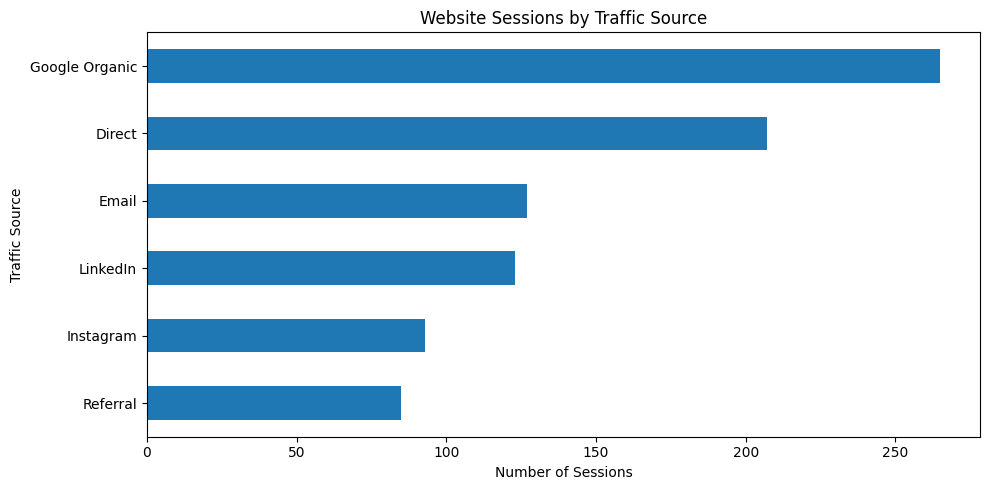

In [24]:
plt.figure(figsize=(10,5))

source_analysis['Total_Sessions'].sort_values().plot(
    kind='barh'
)

plt.title('Website Sessions by Traffic Source')
plt.xlabel('Number of Sessions')
plt.ylabel('Traffic Source')
plt.tight_layout()
plt.show()

In [25]:
device_analysis = df.groupby('DeviceCategory').agg(
    Total_Sessions=('SessionID', 'count'),
    Total_Pageviews=('PageViews', 'sum'),
    Registrations=('Registered', 'sum'),
    Avg_Duration=('SessionDurationSec', 'mean'),
    Bounced_Sessions=('Bounced', 'sum')
)

device_analysis['Conversion_Rate'] = (
    device_analysis['Registrations'] /
    device_analysis['Total_Sessions'] * 100
)

device_analysis['Bounce_Rate'] = (
    device_analysis['Bounced_Sessions'] /
    device_analysis['Total_Sessions'] * 100
)

display(device_analysis.round(2))

,Total_Sessions,Total_Pageviews,Registrations,Avg_Duration,Bounced_Sessions,Conversion_Rate,Bounce_Rate
DeviceCategory,,,,,,,
Desktop,261,910,57,247.59,12,21.84,4.60
Mobile,593,2047,104,242.26,30,17.54,5.06
Tablet,46,151,5,236.04,2,10.87,4.35


In [26]:
print("Highest Traffic Device:",
      device_analysis['Total_Sessions'].idxmax())

print("\nHighest Registration Device:",
      device_analysis['Registrations'].idxmax())

print("\nHighest Conversion Rate Device:",
      device_analysis['Conversion_Rate'].idxmax())

Highest Traffic Device: Mobile

Highest Registration Device: Mobile

Highest Conversion Rate Device: Desktop


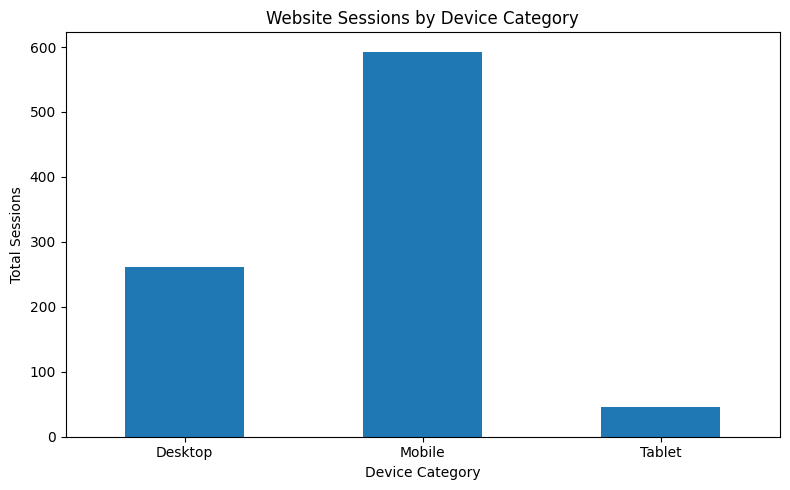

In [27]:
plt.figure(figsize=(8,5))

device_analysis['Total_Sessions'].plot(
    kind='bar'
)

plt.title('Website Sessions by Device Category')
plt.xlabel('Device Category')
plt.ylabel('Total Sessions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
total_sessions = len(df)
registration_started = df['StartedRegistration'].sum()
registration_completed = df['Registered'].sum()

not_started = total_sessions - registration_started

dropped_before_completion = (
    registration_started - registration_completed
)

completion_rate = (
    registration_completed / registration_started
) * 100

dropoff_rate = (
    dropped_before_completion / registration_started
) * 100

print("REGISTRATION FUNNEL ANALYSIS")
print("--------------------------------")
print("Total Sessions:", total_sessions)
print("Registration Started:", registration_started)
print("Registration Completed:", registration_completed)
print("Visitors Who Did Not Start:", not_started)
print("Registration Drop-offs:", dropped_before_completion)
print("Registration Completion Rate:", round(completion_rate, 2), "%")
print("Registration Drop-off Rate:", round(dropoff_rate, 2), "%")

REGISTRATION FUNNEL ANALYSIS
--------------------------------
Total Sessions: 900
Registration Started: 277
Registration Completed: 166
Visitors Who Did Not Start: 623
Registration Drop-offs: 111
Registration Completion Rate: 59.93 %
Registration Drop-off Rate: 40.07 %


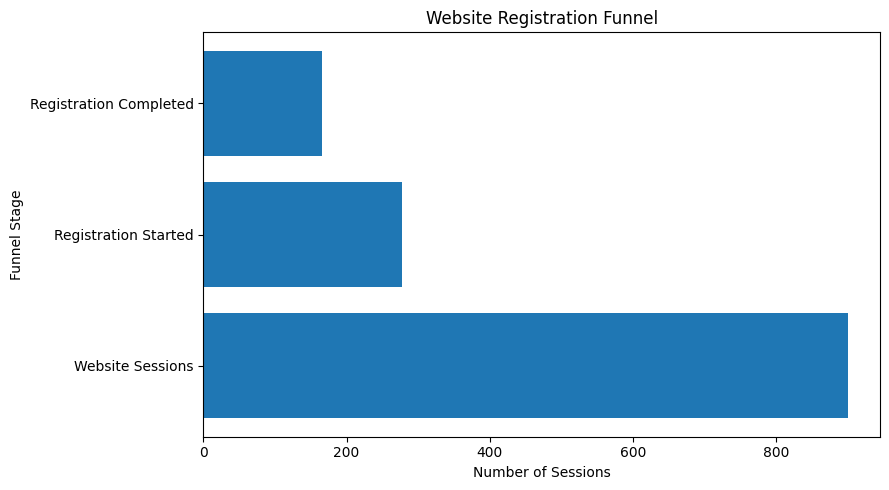

In [29]:
funnel = pd.Series({
    'Website Sessions': total_sessions,
    'Registration Started': registration_started,
    'Registration Completed': registration_completed
})

plt.figure(figsize=(9,5))
plt.barh(funnel.index, funnel.values)

plt.title('Website Registration Funnel')
plt.xlabel('Number of Sessions')
plt.ylabel('Funnel Stage')
plt.tight_layout()
plt.show()

In [30]:
landing_analysis = df.groupby('LandingPage').agg(
    Total_Sessions=('SessionID', 'count'),
    Registrations=('Registered', 'sum'),
    Avg_Duration=('SessionDurationSec', 'mean'),
    Bounce_Count=('Bounced', 'sum')
)

landing_analysis['Conversion_Rate'] = (
    landing_analysis['Registrations'] /
    landing_analysis['Total_Sessions'] * 100
)

landing_analysis['Bounce_Rate'] = (
    landing_analysis['Bounce_Count'] /
    landing_analysis['Total_Sessions'] * 100
)

display(landing_analysis.round(2))

,Total_Sessions,Registrations,Avg_Duration,Bounce_Count,Conversion_Rate,Bounce_Rate
LandingPage,,,,,,
/,161,21,254.91,12,13.04,7.45
/faq,144,26,224.83,5,18.06,3.47
/login,144,33,247.70,3,22.92,2.08
/programs,161,29,256.06,5,18.01,3.11
/register,151,29,235.86,8,19.21,5.30
/verify,139,28,238.94,11,20.14,7.91


In [31]:
print("Highest Traffic Landing Page:")
print(landing_analysis['Total_Sessions'].idxmax())

print("\nHighest Registration Landing Page:")
print(landing_analysis['Registrations'].idxmax())

print("\nHighest Conversion Landing Page:")
print(landing_analysis['Conversion_Rate'].idxmax())

Highest Traffic Landing Page:
/

Highest Registration Landing Page:
/login

Highest Conversion Landing Page:
/login


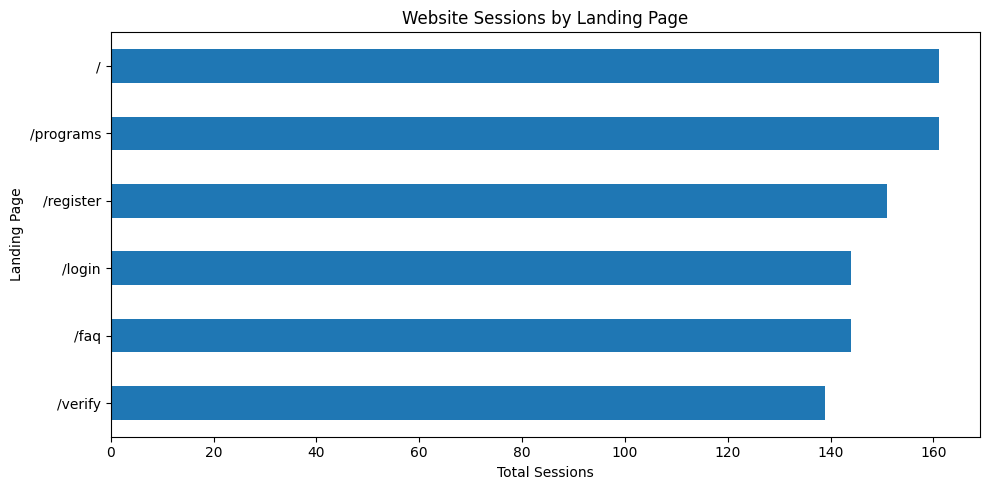

In [32]:
plt.figure(figsize=(10, 5))

landing_analysis['Total_Sessions'].sort_values().plot(
    kind='barh'
)

plt.title('Website Sessions by Landing Page')
plt.xlabel('Total Sessions')
plt.ylabel('Landing Page')
plt.tight_layout()
plt.show()

In [33]:
campaign_analysis = df.groupby('Campaign').agg(
    Total_Sessions=('SessionID', 'count'),
    Registrations=('Registered', 'sum'),
    Registration_Starts=('StartedRegistration', 'sum'),
    Avg_Duration=('SessionDurationSec', 'mean'),
    Bounced_Sessions=('Bounced', 'sum')
)

campaign_analysis['Conversion_Rate'] = (
    campaign_analysis['Registrations'] /
    campaign_analysis['Total_Sessions'] * 100
)

campaign_analysis['Bounce_Rate'] = (
    campaign_analysis['Bounced_Sessions'] /
    campaign_analysis['Total_Sessions'] * 100
)

display(campaign_analysis.round(2))

,Total_Sessions,Registrations,Registration_Starts,Avg_Duration,Bounced_Sessions,Conversion_Rate,Bounce_Rate
Campaign,,,,,,,
campus,215,33,65,237.42,11,15.35,5.12
career-week,220,49,75,239.05,12,22.27,5.45
none,235,37,69,241.49,10,15.74,4.26
starter,230,47,68,255.43,11,20.43,4.78


In [34]:
print("Highest Traffic Campaign:")
print(campaign_analysis['Total_Sessions'].idxmax())

print("\nHighest Registration Campaign:")
print(campaign_analysis['Registrations'].idxmax())

print("\nHighest Conversion Campaign:")
print(campaign_analysis['Conversion_Rate'].idxmax())

Highest Traffic Campaign:
none

Highest Registration Campaign:
career-week

Highest Conversion Campaign:
career-week


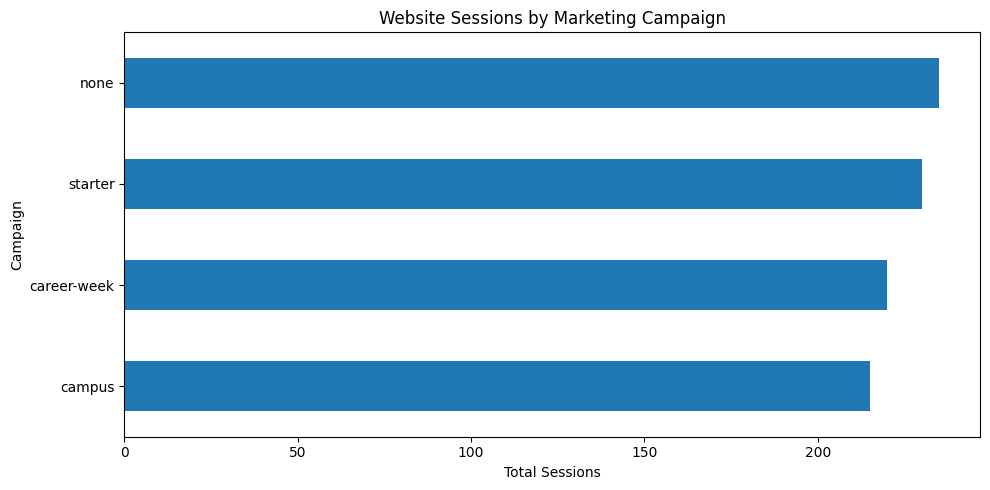

In [35]:
plt.figure(figsize=(10,5))

campaign_analysis['Total_Sessions'].sort_values().plot(
    kind='barh'
)

plt.title('Website Sessions by Marketing Campaign')
plt.xlabel('Total Sessions')
plt.ylabel('Campaign')
plt.tight_layout()
plt.show()

In [36]:
campaign_analysis = df.groupby('Campaign').agg(
    Sessions=('SessionID', 'count'),
    Registrations=('Registered', 'sum'),
    Avg_Duration=('SessionDurationSec', 'mean')
)

campaign_analysis['Conversion_Rate'] = (
    campaign_analysis['Registrations'] /
    campaign_analysis['Sessions'] * 100
)

display(campaign_analysis.round(2))

print("Best Traffic Campaign:",
      campaign_analysis['Sessions'].idxmax())

print("Best Registration Campaign:",
      campaign_analysis['Registrations'].idxmax())

print("Best Conversion Campaign:",
      campaign_analysis['Conversion_Rate'].idxmax())

,Sessions,Registrations,Avg_Duration,Conversion_Rate
Campaign,,,,
campus,215,33,237.42,15.35
career-week,220,49,239.05,22.27
none,235,37,241.49,15.74
starter,230,47,255.43,20.43


Best Traffic Campaign: none
Best Registration Campaign: career-week
Best Conversion Campaign: career-week


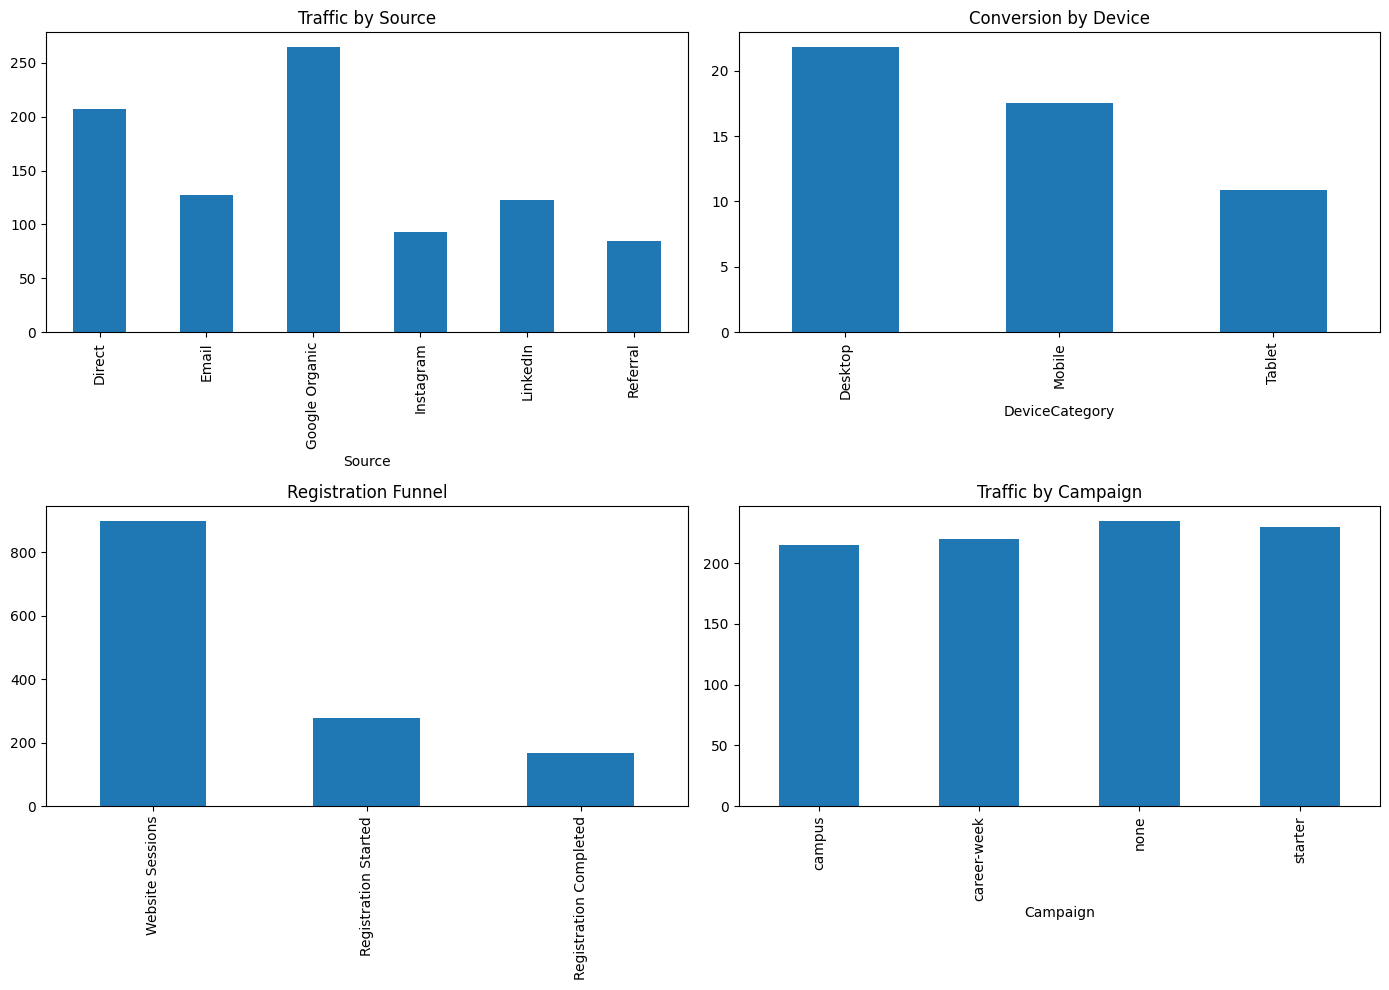

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Traffic by source
source_analysis['Total_Sessions'].plot(
    kind='bar', ax=axes[0, 0], title='Traffic by Source'
)

# Conversion by device
device_analysis['Conversion_Rate'].plot(
    kind='bar', ax=axes[0, 1], title='Conversion by Device'
)

# Registration funnel
funnel.plot(
    kind='bar', ax=axes[1, 0], title='Registration Funnel'
)

# Traffic by campaign
campaign_analysis['Sessions'].plot(
    kind='bar', ax=axes[1, 1], title='Traffic by Campaign'
)

plt.tight_layout()
plt.show()

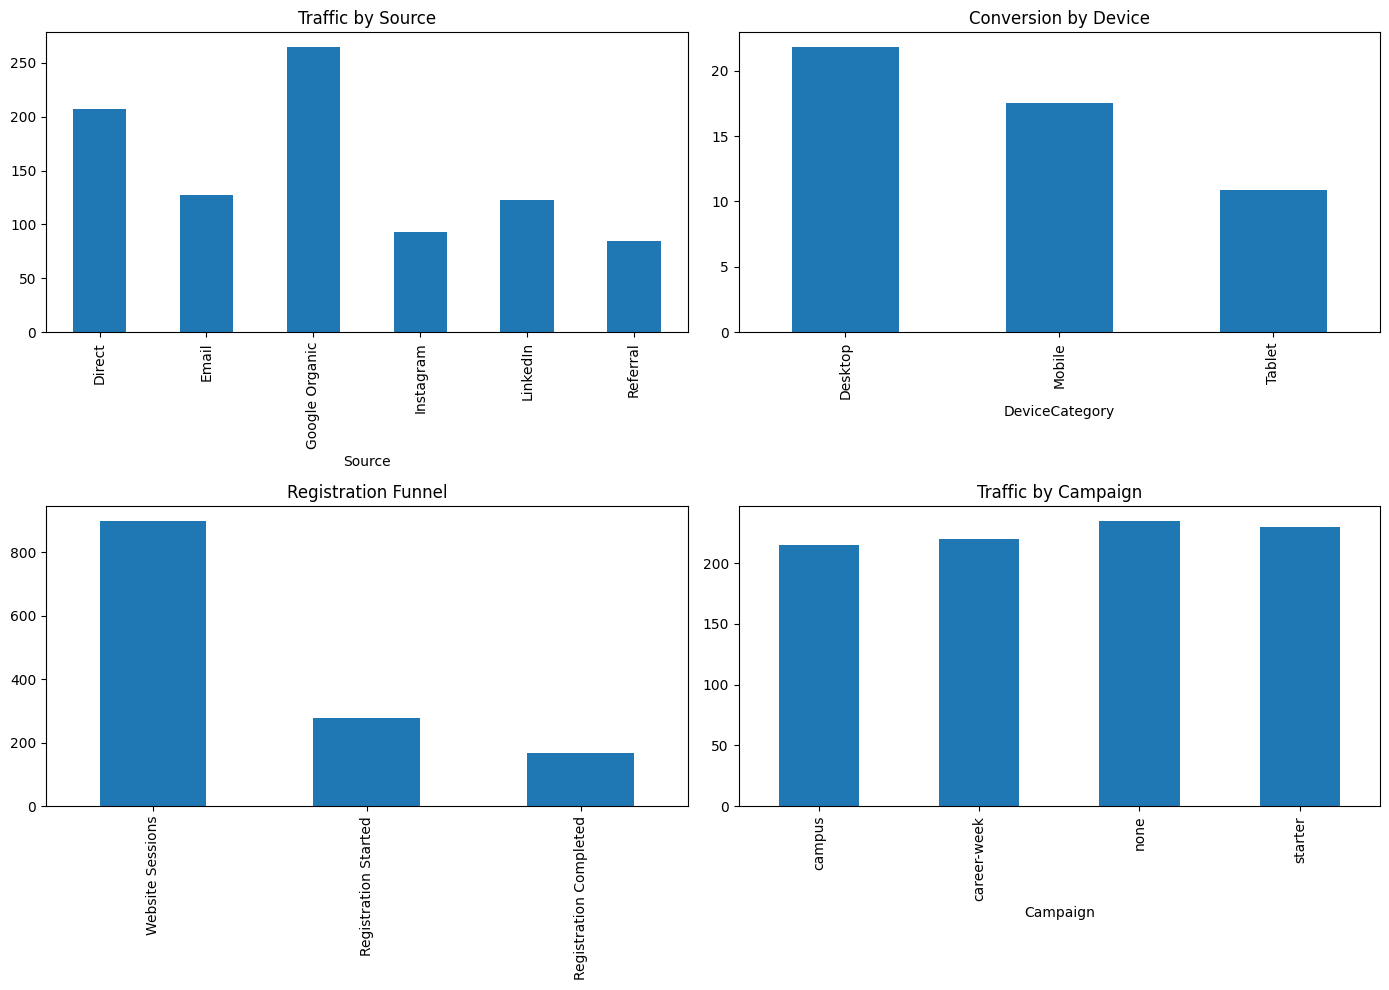

All project files generated successfully!


In [38]:
# FINAL PROJECT SUMMARY

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Create final dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

source_analysis['Total_Sessions'].plot(
    kind='bar', ax=axes[0, 0], title='Traffic by Source'
)

device_analysis['Conversion_Rate'].plot(
    kind='bar', ax=axes[0, 1], title='Conversion by Device'
)

funnel.plot(
    kind='bar', ax=axes[1, 0], title='Registration Funnel'
)

campaign_analysis['Sessions'].plot(
    kind='bar', ax=axes[1, 1], title='Traffic by Campaign'
)

plt.tight_layout()

# Save dashboard
plt.savefig('Web_Traffic_Dashboard.png', dpi=300)
plt.show()

# Save analysis tables
with pd.ExcelWriter('Web_Traffic_Analysis.xlsx') as writer:
    source_analysis.to_excel(writer, sheet_name='Traffic Sources')
    device_analysis.to_excel(writer, sheet_name='Devices')
    landing_analysis.to_excel(writer, sheet_name='Landing Pages')
    campaign_analysis.to_excel(writer, sheet_name='Campaigns')

# Create PDF report
with PdfPages('Web_Traffic_Analytics_Report.pdf') as pdf:
    fig = plt.figure(figsize=(11, 8.5))
    plt.axis('off')

    report = """
    WEB TRAFFIC ANALYTICS REPORT

    Total Sessions: 900
    Total Pageviews: 3108
    Average Session Duration: 243.49 seconds
    Bounce Rate: 4.89%
    Registration Start Rate: 30.78%
    Conversion Rate: 18.44%

    TRAFFIC INSIGHTS
    Highest Traffic Source: Google Organic
    Highest Registration Source: Google Organic
    Highest Conversion Source: Instagram

    DEVICE INSIGHTS
    Highest Traffic Device: Mobile
    Highest Conversion Device: Desktop

    REGISTRATION FUNNEL
    Registration Started: 277
    Registration Completed: 166
    Registration Drop-offs: 111
    Completion Rate: 59.93%
    Drop-off Rate: 40.07%

    LANDING PAGE INSIGHTS
    Highest Traffic: /
    Highest Registrations: /login
    Highest Conversion: /login

    CAMPAIGN INSIGHTS
    Highest Traffic Campaign: none
    Best Registration Campaign: career-week
    Best Conversion Campaign: career-week

    BUSINESS RECOMMENDATIONS
    1. Improve mobile conversion performance.
    2. Simplify the registration process.
    3. Optimize the homepage.
    4. Invest in successful marketing campaigns.
    5. Investigate registration drop-offs.
    """

    plt.text(0.08, 0.92, report, va='top',
             fontsize=11, family='monospace')

    pdf.savefig(fig)
    plt.close(fig)

    pdf.savefig(plt.figure(figsize=(14, 10)))
    plt.close()

print("All project files generated successfully!")

In [39]:
from google.colab import files
import os

print("Generated files:")
for file in [
    'Web_Traffic_Analytics_Report.pdf',
    'Web_Traffic_Analysis.xlsx',
    'Web_Traffic_Dashboard.png'
]:
    if os.path.exists(file):
        print("✅", file)
    else:
        print("❌ Missing:", file)

Generated files:
✅ Web_Traffic_Analytics_Report.pdf
✅ Web_Traffic_Analysis.xlsx
✅ Web_Traffic_Dashboard.png


In [40]:
files.download('Web_Traffic_Analytics_Report.pdf')
files.download('Web_Traffic_Analysis.xlsx')
files.download('Web_Traffic_Dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
!pip -q install reportlab

from reportlab.platypus import *
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet

doc = SimpleDocTemplate(
    "Web_Traffic_Analytics_Report.pdf",
    pagesize=A4
)

styles = getSampleStyleSheet()
content = []

content.append(Paragraph(
    "WEB TRAFFIC ANALYTICS REPORT",
    styles['Title']
))

sections = [
    ("PROJECT OVERVIEW",
     "Analysis of 900 website visits and 12 variables."),

    ("KEY PERFORMANCE INDICATORS",
     "Sessions: 900 | Pageviews: 3108<br/>"
     "Average Duration: 243.49 seconds<br/>"
     "Bounce Rate: 4.89%<br/>"
     "Registration Start Rate: 30.78%<br/>"
     "Conversion Rate: 18.44%"),

    ("TRAFFIC INSIGHTS",
     "Highest Traffic: Google Organic<br/>"
     "Highest Registrations: Google Organic<br/>"
     "Highest Conversion: Instagram (23.66%)"),

    ("DEVICE INSIGHTS",
     "Highest Traffic: Mobile<br/>"
     "Highest Conversion: Desktop (21.84%)"),

    ("REGISTRATION FUNNEL",
     "Registration Started: 277<br/>"
     "Completed: 166<br/>"
     "Drop-offs: 111<br/>"
     "Completion Rate: 59.93%<br/>"
     "Drop-off Rate: 40.07%"),

    ("LANDING PAGE & CAMPAIGN",
     "Best Landing Page: /login<br/>"
     "Best Campaign: career-week<br/>"
     "Campaign Conversion: 22.27%"),

    ("RECOMMENDATIONS",
     "1. Improve mobile experience.<br/>"
     "2. Simplify registration.<br/>"
     "3. Optimize homepage.<br/>"
     "4. Improve high-performing campaigns.<br/>"
     "5. Reduce registration drop-offs.")
]

for heading, text in sections:
    content.append(Paragraph(heading, styles['Heading2']))
    content.append(Paragraph(text, styles['BodyText']))
    content.append(Spacer(1, 15))

doc.build(content)

from google.colab import files
files.download("Web_Traffic_Analytics_Report.pdf")

print("Professional PDF created!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Professional PDF created!


In [42]:
import os

print(os.path.exists("Web_Traffic_Analytics_Report.pdf"))

True


In [44]:
from google.colab import files

files.download("Web_Traffic_Analytics_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>